<a href="https://colab.research.google.com/github/Yashikaysn/ecommerce-funnel-analysis/blob/main/ecommerce_funnel_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!ls -lh events.csv

ls: cannot access 'events.csv': No such file or directory


In [4]:
import pandas as pd
import sqlite3

df = pd.read_csv("events.csv")
df["event_time"] = pd.to_datetime(df["timestamp"], unit="ms")

conn = sqlite3.connect("funnel.db")
df.to_sql("events", conn, if_exists="replace", index=False)

print("Rows loaded:", len(df))

Rows loaded: 2756101


In [5]:
pd.read_sql("""
SELECT event,
       COUNT(*) AS total_events,
       COUNT(DISTINCT visitorid) AS unique_users
FROM events
GROUP BY event
""", conn)

,event,total_events,unique_users
0,addtocart,69332,37722
1,transaction,22457,11719
2,view,2664312,1404179


In [6]:
funnel = pd.read_sql("""
WITH user_steps AS (
    SELECT visitorid,
           MAX(event = 'view')        AS viewed,
           MAX(event = 'addtocart')   AS carted,
           MAX(event = 'transaction') AS bought
    FROM events
    GROUP BY visitorid
)
SELECT
  SUM(viewed) AS step1_viewers,
  SUM(CASE WHEN viewed = 1 AND carted = 1 THEN 1 ELSE 0 END) AS step2_carted,
  SUM(CASE WHEN viewed = 1 AND carted = 1 AND bought = 1 THEN 1 ELSE 0 END) AS step3_bought
FROM user_steps
""", conn)

funnel

,step1_viewers,step2_carted,step3_bought
0,1404179,34401,10228


In [7]:
funnel["view_to_cart_%"] = (funnel["step2_carted"] / funnel["step1_viewers"] * 100).round(2)
funnel["cart_to_buy_%"] = (funnel["step3_bought"] / funnel["step2_carted"] * 100).round(2)
funnel["view_to_buy_%"] = (funnel["step3_bought"] / funnel["step1_viewers"] * 100).round(2)

funnel

,step1_viewers,step2_carted,step3_bought,view_to_cart_%,cart_to_buy_%,view_to_buy_%
0,1404179,34401,10228,2.45,29.73,0.73


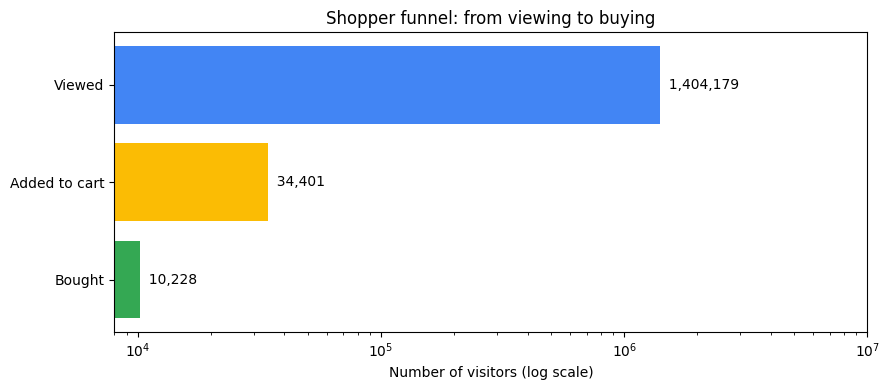

In [8]:
import matplotlib.pyplot as plt

stages = ["Viewed", "Added to cart", "Bought"]
counts = [int(funnel.loc[0, "step1_viewers"]),
          int(funnel.loc[0, "step2_carted"]),
          int(funnel.loc[0, "step3_bought"])]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(stages[::-1], counts[::-1], color=["#34a853", "#fbbc04", "#4285f4"])
ax.set_xscale("log")
for i, c in enumerate(counts[::-1]):
    ax.text(c, i, f"  {c:,}", va="center")
ax.set_title("Shopper funnel: from viewing to buying")
ax.set_xlabel("Number of visitors (log scale)")
ax.set_xlim(right=1e7)
plt.tight_layout()
plt.savefig("funnel_chart.png", dpi=150)
plt.show()

In [9]:
hourly = pd.read_sql("""
SELECT strftime('%H', event_time) AS hour,
       SUM(event = 'view')        AS views,
       SUM(event = 'addtocart')   AS carts,
       SUM(event = 'transaction') AS buys,
       ROUND(100.0 * SUM(event = 'addtocart') / SUM(event = 'view'), 2) AS cart_rate_pct,
       ROUND(100.0 * SUM(event = 'transaction') / SUM(event = 'addtocart'), 2) AS buy_per_cart_pct
FROM events
GROUP BY hour
ORDER BY hour
""", conn)

hourly

,hour,views,carts,buys,cart_rate_pct,buy_per_cart_pct
0,00,139459,3725,1119,2.67,30.04
1,01,136087,3578,1037,2.63,28.98
2,02,141530,3337,1012,2.36,30.33
3,03,146758,3266,836,2.23,25.60
4,04,143296,3141,747,2.19,23.78
5,05,116039,2786,747,2.40,26.81
6,06,74692,1803,477,2.41,26.46
7,07,42638,1028,278,2.41,27.04
8,08,24663,540,106,2.19,19.63
9,09,17440,399,70,2.29,17.54


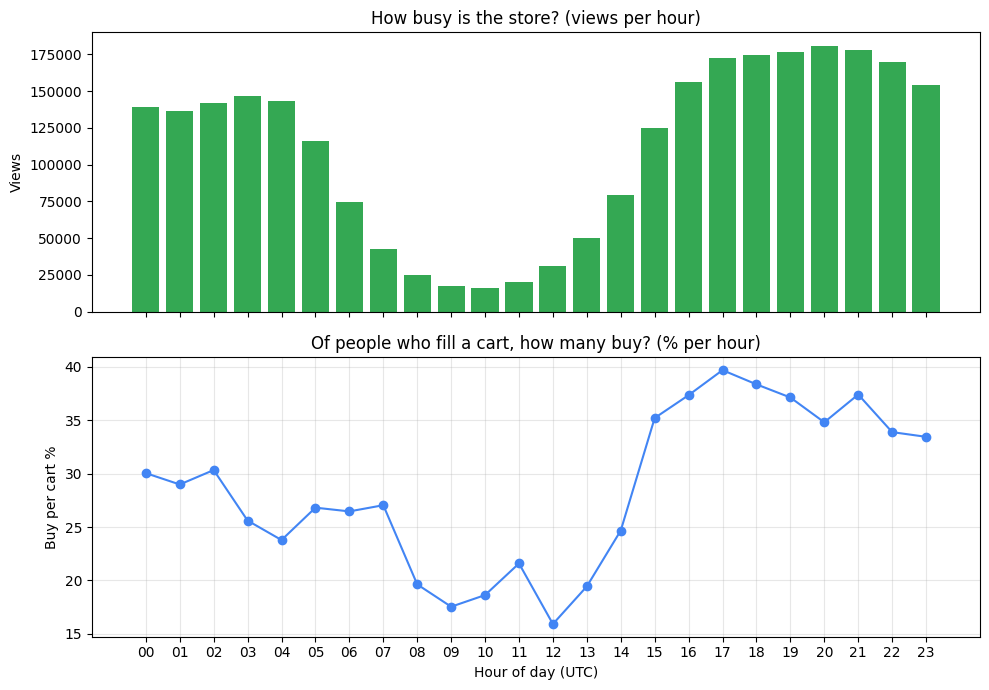

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax1.bar(hourly["hour"], hourly["views"], color="#34a853")
ax1.set_title("How busy is the store? (views per hour)")
ax1.set_ylabel("Views")

ax2.plot(hourly["hour"], hourly["buy_per_cart_pct"], marker="o", color="#4285f4")
ax2.set_title("Of people who fill a cart, how many buy? (% per hour)")
ax2.set_ylabel("Buy per cart %")
ax2.set_xlabel("Hour of day (UTC)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("hourly_chart.png", dpi=150)
plt.show()

In [11]:
leaks = pd.read_sql("""
WITH pairs AS (
    SELECT visitorid, itemid,
           MAX(event = 'addtocart')   AS carted,
           MAX(event = 'transaction') AS bought
    FROM events
    WHERE event IN ('addtocart', 'transaction')
    GROUP BY visitorid, itemid
)
SELECT itemid,
       SUM(carted) AS times_carted,
       SUM(CASE WHEN carted = 1 AND bought = 1 THEN 1 ELSE 0 END) AS times_bought,
       SUM(carted) - SUM(CASE WHEN carted = 1 AND bought = 1 THEN 1 ELSE 0 END) AS abandoned,
       ROUND(100.0 * SUM(CASE WHEN carted = 1 AND bought = 1 THEN 1 ELSE 0 END) / SUM(carted), 2) AS buy_rate_pct
FROM pairs
WHERE carted = 1
GROUP BY itemid
HAVING SUM(carted) >= 20
ORDER BY abandoned DESC
LIMIT 15
""", conn)

leaks

,itemid,times_carted,times_bought,abandoned,buy_rate_pct
0,461686,267,120,147,44.94
1,320130,131,24,107,18.32
2,312728,129,24,105,18.60
3,409804,128,28,100,21.88
4,29196,101,13,88,12.87
5,441852,82,20,62,24.39
6,316753,70,11,59,15.71
7,279457,62,5,57,8.06
8,257040,79,22,57,27.85
9,234255,69,16,53,23.19


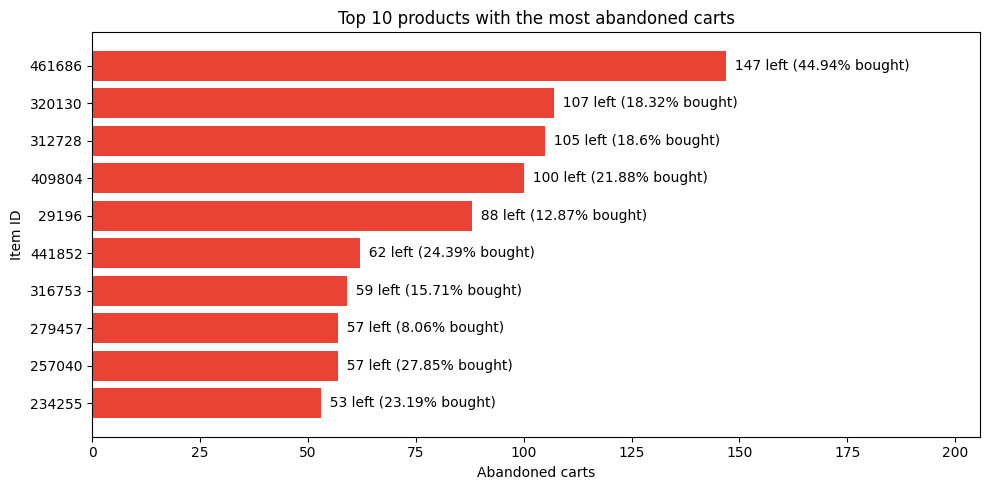

In [12]:
top = leaks.head(10).copy()
top["itemid"] = top["itemid"].astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["itemid"][::-1], top["abandoned"][::-1], color="#ea4335")
for i, (a, r) in enumerate(zip(top["abandoned"][::-1], top["buy_rate_pct"][::-1])):
    ax.text(a, i, f"  {a} left ({r}% bought)", va="center")
ax.set_title("Top 10 products with the most abandoned carts")
ax.set_xlabel("Abandoned carts")
ax.set_ylabel("Item ID")
ax.set_xlim(right=top["abandoned"].max() * 1.4)
plt.tight_layout()
plt.savefig("product_leaks_chart.png", dpi=150)
plt.show()

In [13]:
problem = leaks[leaks["buy_rate_pct"] < 20].copy()

target_rate = 30
problem["extra_sales_if_fixed"] = (
    problem["times_carted"] * target_rate / 100 - problem["times_bought"]
).round(0)

print("Total extra sales:", int(problem["extra_sales_if_fixed"].sum()))
problem[["itemid", "times_carted", "times_bought", "buy_rate_pct", "extra_sales_if_fixed"]]

Total extra sales: 99


,itemid,times_carted,times_bought,buy_rate_pct,extra_sales_if_fixed
1,320130,131,24,18.32,15.0
2,312728,129,24,18.60,15.0
4,29196,101,13,12.87,17.0
6,316753,70,11,15.71,10.0
7,279457,62,5,8.06,14.0
11,158666,59,8,13.56,10.0
12,339703,57,7,12.28,10.0
14,390591,51,7,13.73,8.0
